# 🔍 AI-Powered Lost & Found Matcher
### College-Level Machine Learning Project
**Domain:** Artificial Intelligence & Machine Learning / Natural Language Processing  
**Frontend/Execution:** Interactive Jupyter Notebook & Streamlit Web Application  
**Algorithms Used:**
1. **Multiclass Classification:** Random Forest Classifier (Scikit-Learn)
2. **Text Representation & Similarity:** TF-IDF Vectorizer + Cosine Similarity
3. **Binary Classification:** Logistic Regression (Scikit-Learn)
4. **Unsupervised Learning:** K-Means Clustering + PCA 2D Visualization
5. **Database:** SQLite3 for persistent storage

---

### 🎯 Main Objective
Build a complete Machine Learning system that helps people find their lost belongings on a university campus by matching lost-item reports with found-item reports.

For example:
- A student reports a lost *black leather wallet* near the central library.
- Another student reports finding a *dark leather wallet* near the library tables.
- The system automatically extracts semantic features, compares both reports, and predicts whether they form a **Potential Match** with an explainable matching score.

> ⚠️ **Important Viva Principle:** Machine Learning outputs are probabilistic indicators to assist human verification. The system predicts **"Potential Match"**, never a legal guarantee of ownership.


## 📦 Step 1: Environment Setup & Library Imports
We import standard, beginner-friendly Python data science libraries:
- `pandas` and `numpy` for data manipulation
- `matplotlib` and `seaborn` for visualizations
- `sklearn` (Scikit-Learn) for all traditional ML algorithms
- `sqlite3` for local persistent storage


In [1]:
import os
import re
import random
import sqlite3
import joblib
import warnings
from datetime import datetime, date

# Data handling & visualization
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Scikit-Learn Machine Learning algorithms
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score

# Styling preferences
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
sns.set_palette('deep')
warnings.filterwarnings('ignore')

# Set random seed for reproducibility
random.seed(42)
np.random.seed(42)

print("✅ All required libraries imported successfully!")


✅ All required libraries imported successfully!


## 📊 Step 2: Dataset Generation & Exploratory Data Analysis (EDA)

We use two clean, curated datasets designed for campus lost and found scenarios:
1. `items_dataset.csv`: Contains item descriptions labeled with 7 categories:
   - **Wallet**, **Mobile Phone**, **Bag**, **Laptop**, **Watch**, **Keys**, **Other**
2. `matching_dataset.csv`: Contains pairs of lost and found items labeled with ground-truth binary match:
   - `1` = Potential Match
   - `0` = Not a Match


In [2]:
# Ensure data directory exists
os.makedirs("data", exist_ok=True)
os.makedirs("models", exist_ok=True)
os.makedirs("uploads", exist_ok=True)

# Generate or load items dataset
from generate_dataset import generate_items_dataset, generate_matching_dataset

# Generate datasets if not already present
items_csv = "data/items_dataset.csv"
matching_csv = "data/matching_dataset.csv"

if not os.path.exists(items_csv) or not os.path.exists(matching_csv):
    print("Generating datasets...")
    df_items = generate_items_dataset()
    df_matching = generate_matching_dataset()
else:
    df_items = pd.read_csv(items_csv)
    df_matching = pd.read_csv(matching_csv)

print(f"Total Item Records: {len(df_items)}")
print(f"Total Matching Pair Records: {len(df_matching)}")

# Display first few rows of items dataset
df_items.head()


Total Item Records: 315
Total Matching Pair Records: 225


### Exploratory Data Analysis: Visualizing Category Distribution
Let's inspect the balance across all 7 categories in our training dataset.


Category Breakdown:
category
Other           45
Mobile Phone    45
Keys            45
Bag             45
Laptop          45
Wallet          45
Watch           45
Name: count, dtype: int64


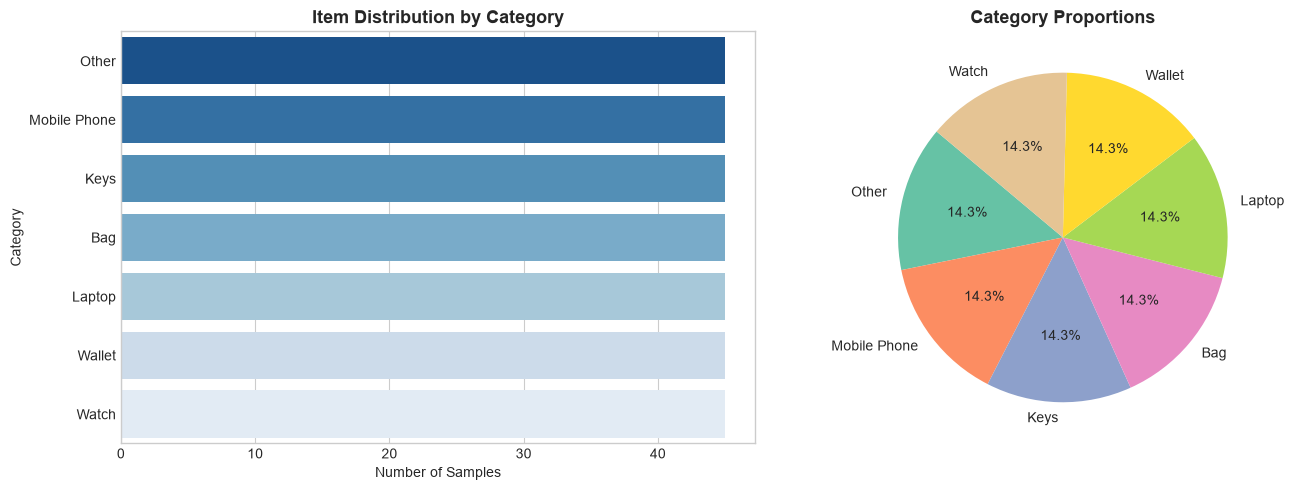

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Bar Chart of Categories
cat_counts = df_items["category"].value_counts()
sns.barplot(x=cat_counts.values, y=cat_counts.index, palette="Blues_r", ax=axes[0])
axes[0].set_title("Item Distribution by Category", fontsize=13, fontweight='bold')
axes[0].set_xlabel("Number of Samples")
axes[0].set_ylabel("Category")

# 2. Pie Chart of Categories
axes[1].pie(cat_counts.values, labels=cat_counts.index, autopct="%1.1f%%", startangle=140, colors=sns.color_palette("Set2"))
axes[1].set_title("Category Proportions", fontsize=13, fontweight='bold')

plt.tight_layout()
plt.show()

# Display summary statistics
print("Category Breakdown:")
print(cat_counts)


## 🔤 Step 3: Text Preprocessing & TF-IDF Vectorization

### Why Preprocess Text?
Raw text contains punctuation, uppercase/lowercase variations, and filler words (*stopwords*) like *"the"*, *"is"*, *"in"*, *"at"* that add noise.
We apply:
1. **Lowercasing**: Unifies case sensitivity (`"iPhone"` == `"iphone"`).
2. **Regex Cleaning**: Strips special symbols, brackets, and punctuation.
3. **Stopword Removal**: Eliminates common English filler words.

### TF-IDF (Term Frequency - Inverse Document Frequency)
Computers cannot understand raw words directly; they require numbers.
- **TF (Term Frequency)**: How often a word appears in a specific description.
- **IDF (Inverse Document Frequency)**: Downweights words appearing everywhere (e.g., *"lost"*, *"found"*) and amplifies distinctive keywords (e.g., *"Casio"*, *"AirPods"*, *"Inspiron"*).

$$\text{TF-IDF}(t, d, D) = \text{TF}(t, d) \times \log\left(\frac{|D|}{1 + |\{d \in D : t \in d\}|}\right)$$


In [4]:
# Self-contained stopwords set
STOPWORDS = set([
    "a", "about", "above", "after", "again", "against", "all", "am", "an", "and", "any", "are", "aren't",
    "as", "at", "be", "because", "been", "before", "being", "below", "between", "both", "but", "by",
    "can't", "cannot", "could", "did", "do", "does", "doing", "don't", "down", "during", "each", "few",
    "for", "from", "further", "had", "has", "have", "having", "he", "her", "here", "hers", "him", "his",
    "how", "i", "if", "in", "into", "is", "isn't", "it", "its", "me", "more", "most", "my", "myself",
    "no", "nor", "not", "of", "off", "on", "once", "only", "or", "other", "our", "ours", "out", "over",
    "own", "same", "she", "should", "so", "some", "such", "than", "that", "the", "their", "theirs", "them",
    "then", "there", "these", "they", "this", "those", "through", "to", "too", "under", "until", "up",
    "very", "was", "wasn't", "we", "were", "what", "when", "where", "which", "while", "who", "whom",
    "why", "with", "would", "you", "your", "yours"
])

def clean_text(text: str) -> str:
    """Cleans raw text for NLP models."""
    if not isinstance(text, str):
        return ""
    text = text.lower()
    text = re.sub(r"[^a-zA-Z0-9\s]", " ", text)
    tokens = text.split()
    filtered = [t for t in tokens if t not in STOPWORDS and len(t) > 1]
    return " ".join(filtered)

# Demonstration of text preprocessing
sample_raw = "Lost my Midnight Blue iPhone 13 (cracked screen!) near Central Library on 2nd floor."
sample_clean = clean_text(sample_raw)

print("Original Text :", sample_raw)
print("Cleaned Text  :", sample_clean)


Original Text : Lost my Midnight Blue iPhone 13 (cracked screen!) near Central Library on 2nd floor.
Cleaned Text  : lost midnight blue iphone 13 cracked screen near central library 2nd floor


### Fitting the TF-IDF Vectorizer
Let's transform all item descriptions into numerical TF-IDF feature matrices.


TF-IDF Vocabulary Size: 1000 words/n-grams
Feature Matrix Shape  : (315, 1000)


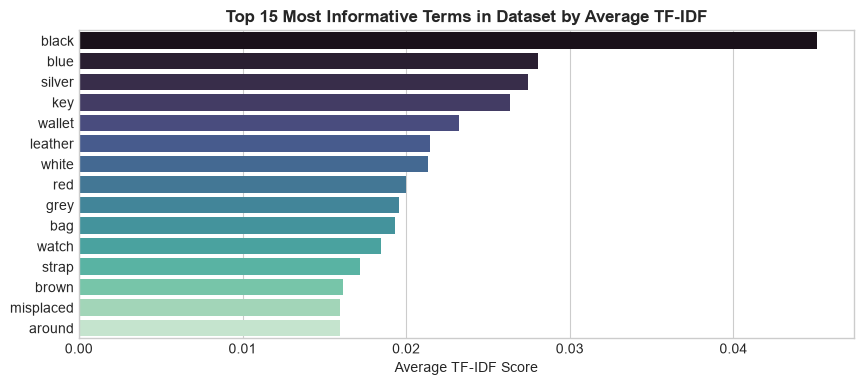

In [5]:
df_items["clean_desc"] = df_items["description"].apply(clean_text)

# Fit TF-IDF Vectorizer
tfidf = TfidfVectorizer(max_features=1000, ngram_range=(1, 2))
X_tfidf_all = tfidf.fit_transform(df_items["clean_desc"])

print(f"TF-IDF Vocabulary Size: {len(tfidf.get_feature_names_out())} words/n-grams")
print(f"Feature Matrix Shape  : {X_tfidf_all.shape}")

# Top 15 highest average TF-IDF terms across all descriptions
avg_tfidf = np.array(X_tfidf_all.mean(axis=0)).flatten()
top_indices = avg_tfidf.argsort()[::-1][:15]
top_terms = [tfidf.get_feature_names_out()[i] for i in top_indices]
top_scores = [avg_tfidf[i] for i in top_indices]

plt.figure(figsize=(10, 4))
sns.barplot(x=top_scores, y=top_terms, palette="mako")
plt.title("Top 15 Most Informative Terms in Dataset by Average TF-IDF", fontweight='bold')
plt.xlabel("Average TF-IDF Score")
plt.show()


## 🌲 Step 4: Algorithm A - Multiclass Classification (Random Forest Classifier)

### Concept:
- **Task**: Predict which of the 7 categories an item belongs to, based on its text description.
- **Why Random Forest?**:
  - It builds an ensemble of multiple **Decision Trees** using bootstrap sampling (*bagging*).
  - Each tree votes on the predicted category; the majority vote wins.
  - Highly robust against overfitting on text data and handles sparse TF-IDF matrices effectively.


In [6]:
# Prepare Features (X) and Target (y)
X = df_items["clean_desc"]
y = df_items["category"]

# 80% Train, 20% Test Split with Stratification
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# Vectorize training and testing sets
vectorizer_rf = TfidfVectorizer(max_features=1000, ngram_range=(1, 2))
X_train_vec = vectorizer_rf.fit_transform(X_train)
X_test_vec = vectorizer_rf.transform(X_test)

# Train Random Forest Classifier
rf_model = RandomForestClassifier(n_estimators=100, max_depth=15, random_state=42)
rf_model.fit(X_train_vec, y_train)

# Evaluate model
y_pred_rf = rf_model.predict(X_test_vec)
rf_accuracy = accuracy_score(y_test, y_pred_rf)
rf_f1 = f1_score(y_test, y_pred_rf, average="weighted")

print(f"🎯 Random Forest Test Accuracy: {rf_accuracy * 100:.2f}%")
print(f"🎯 Weighted F1-Score         : {rf_f1:.4f}\n")
print("Classification Report:")
print(classification_report(y_test, y_pred_rf))

# Save models to disk
joblib.dump(rf_model, "models/category_classifier.pkl")
joblib.dump(vectorizer_rf, "models/category_tfidf.pkl")
print("Saved models to models/ directory.")


🎯 Random Forest Test Accuracy: 98.41%
🎯 Weighted F1-Score         : 0.9841

Classification Report:
              precision    recall  f1-score   support

         Bag       0.90      1.00      0.95         9
        Keys       1.00      1.00      1.00         9
      Laptop       1.00      1.00      1.00         9
Mobile Phone       1.00      1.00      1.00         9
       Other       1.00      0.89      0.94         9
      Wallet       1.00      1.00      1.00         9
       Watch       1.00      1.00      1.00         9

    accuracy                           0.98        63
   macro avg       0.99      0.98      0.98        63
weighted avg       0.99      0.98      0.98        63

Saved models to models/ directory.


### Evaluating Random Forest with a Confusion Matrix
The confusion matrix shows how many items of each category were correctly predicted vs. misclassified.


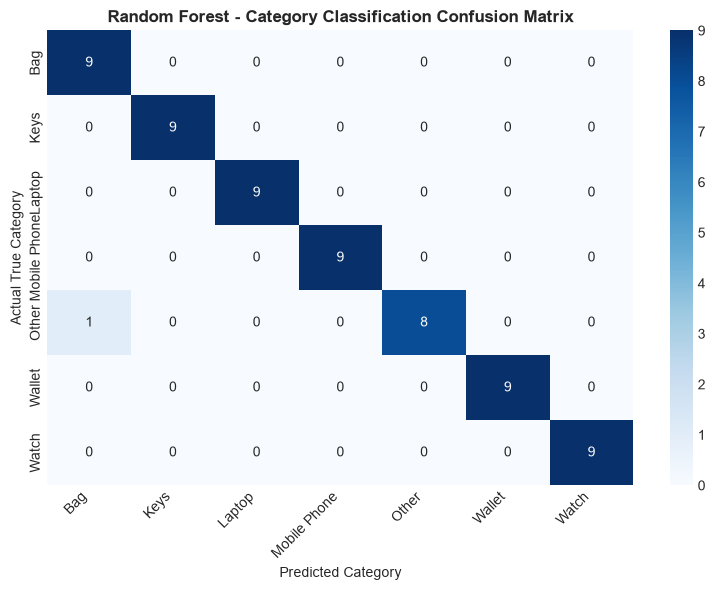

In [7]:
labels = sorted(list(df_items["category"].unique()))
cm = confusion_matrix(y_test, y_pred_rf, labels=labels)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap="Blues", xticklabels=labels, yticklabels=labels)
plt.title("Random Forest - Category Classification Confusion Matrix", fontweight='bold')
plt.xlabel("Predicted Category")
plt.ylabel("Actual True Category")
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()


### Testing Category Prediction on New User Input
Let's test the trained Random Forest classifier on completely unseen descriptions.


In [8]:
def test_predict_category(user_text):
    cleaned = clean_text(user_text)
    vec = vectorizer_rf.transform([cleaned])
    pred_cat = rf_model.predict(vec)[0]
    probs = rf_model.predict_proba(vec)[0]
    conf = float(np.max(probs))
    
    print(f"Input Text: '{user_text}'")
    print(f"➡️ Predicted Category: {pred_cat} (Confidence: {conf*100:.1f}%)\n")
    return pred_cat

# Test cases
test_predict_category("Lost my brown leather cardholder with cash and student ID card")
test_predict_category("Found blue iPhone 13 with cracked tempered glass")
test_predict_category("Wildcraft water-resistant backpack left in lecture hall")
test_predict_category("Silver Dell Inspiron 15 inch laptop with charger")
test_predict_category("Analog stainless steel Casio watch with white dial")
test_predict_category("Bunch of Honda scooter keys with red rubber keychain")
test_predict_category("Casio scientific calculator fx-991EX left on desk")


Input Text: 'Lost my brown leather cardholder with cash and student ID card'
➡️ Predicted Category: Wallet (Confidence: 62.7%)

Input Text: 'Found blue iPhone 13 with cracked tempered glass'
➡️ Predicted Category: Mobile Phone (Confidence: 34.8%)

Input Text: 'Wildcraft water-resistant backpack left in lecture hall'
➡️ Predicted Category: Bag (Confidence: 39.7%)

Input Text: 'Silver Dell Inspiron 15 inch laptop with charger'
➡️ Predicted Category: Laptop (Confidence: 55.6%)

Input Text: 'Analog stainless steel Casio watch with white dial'
➡️ Predicted Category: Watch (Confidence: 65.7%)

Input Text: 'Bunch of Honda scooter keys with red rubber keychain'
➡️ Predicted Category: Keys (Confidence: 44.4%)

Input Text: 'Casio scientific calculator fx-991EX left on desk'
➡️ Predicted Category: Other (Confidence: 25.0%)


## 📐 Step 5: Algorithm B - Text Similarity (TF-IDF + Cosine Similarity)

### Concept:
- **Task**: Quantify the degree of lexical and semantic overlap between a lost item description and a found item description.
- **Formula**:
  $$\text{Cosine Similarity}(\vec{A}, \vec{B}) = \frac{\vec{A} \cdot \vec{B}}{\|\vec{A}\| \|\vec{B}\|}$$
  - Returns `1.0` if two descriptions use the exact same informative words.
  - Returns `0.0` if there is no shared vocabulary.


Cosine Similarity Demonstration:
Pair #1:
  Lost : Black leather wallet lost at library
  Found: Found black leather bi-fold wallet with ID near library tables
  ➡️ Cosine Similarity: 0.4110 (41.1%)

Pair #2:
  Lost : Blue iPhone 13 with cracked glass
  Found: Found iPhone 13 blue color with screen scratch
  ➡️ Cosine Similarity: 0.3446 (34.5%)

Pair #3:
  Lost : Red Nike gym duffle bag with sports shoes
  Found: Red duffle bag found in badminton court
  ➡️ Cosine Similarity: 0.3041 (30.4%)

Pair #4:
  Lost : Dell silver laptop Inspiron 15
  Found: Found emerald green OnePlus phone at cafeteria
  ➡️ Cosine Similarity: 0.0000 (0.0%)


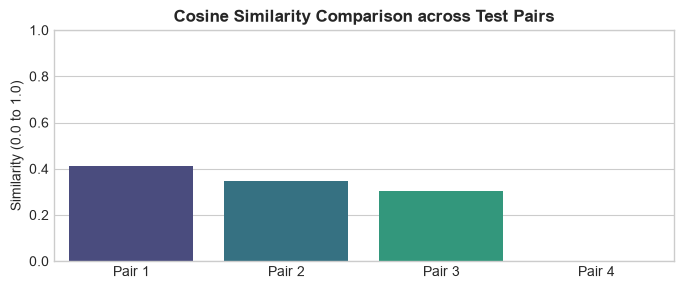

In [9]:
def calculate_cosine_similarity(text1: str, text2: str) -> float:
    c1, c2 = clean_text(text1), clean_text(text2)
    if not c1 or not c2:
        return 0.0
    vec = TfidfVectorizer()
    try:
        matrix = vec.fit_transform([c1, c2])
        sim = cosine_similarity(matrix[0:1], matrix[1:2])[0][0]
        return float(np.clip(sim, 0.0, 1.0))
    except Exception:
        return 0.0

# Compare pairs of descriptions
test_pairs = [
    ("Black leather wallet lost at library", "Found black leather bi-fold wallet with ID near library tables"),
    ("Blue iPhone 13 with cracked glass", "Found iPhone 13 blue color with screen scratch"),
    ("Red Nike gym duffle bag with sports shoes", "Red duffle bag found in badminton court"),
    ("Dell silver laptop Inspiron 15", "Found emerald green OnePlus phone at cafeteria") # Non-matching
]

print("Cosine Similarity Demonstration:")
print("=" * 70)
sim_scores = []
pair_labels = []

for i, (t1, t2) in enumerate(test_pairs, 1):
    score = calculate_cosine_similarity(t1, t2)
    sim_scores.append(score)
    pair_labels.append(f"Pair {i}")
    print(f"Pair #{i}:")
    print(f"  Lost : {t1}")
    print(f"  Found: {t2}")
    print(f"  ➡️ Cosine Similarity: {score:.4f} ({score*100:.1f}%)\n")

plt.figure(figsize=(8, 3))
sns.barplot(x=pair_labels, y=sim_scores, palette="viridis")
plt.title("Cosine Similarity Comparison across Test Pairs", fontweight='bold')
plt.ylabel("Similarity (0.0 to 1.0)")
plt.ylim(0, 1.0)
plt.show()


## ⚖️ Step 6: Algorithm C - Binary Match Classification (Logistic Regression)

### Concept:
- **Task**: Predict whether a pair of reports is a **Potential Match** ($y = 1$) or **Not a Match** ($y = 0$).
- **Why Logistic Regression?**:
  - Extremely fast, stable, and highly **explainable**.
  - Learns linear weights ($w_i$) for each feature and outputs a calibrated probability through the **Sigmoid** function:
  $$P(\text{Match} = 1) = \sigma(z) = \frac{1}{1 + e^{-z}}$$
  where:
  $$z = w_1 \cdot \text{text\_sim} + w_2 \cdot \text{same\_cat} + w_3 \cdot \text{same\_col} + w_4 \cdot \text{same\_loc} + w_5 \cdot \text{date\_diff} + b$$


In [10]:
# Load matching dataset
print(f"Loaded {len(df_matching)} labeled pairs from data/matching_dataset.csv")
print("Target Distribution:")
print(df_matching["is_match"].value_counts())

feature_cols = [
    "text_similarity",
    "same_category",
    "same_color",
    "same_location",
    "date_diff_days"
]

X_match = df_matching[feature_cols]
y_match = df_matching["is_match"]

# Train/Test Split (80/20)
X_train_m, X_test_m, y_train_m, y_test_m = train_test_split(
    X_match, y_match, test_size=0.20, random_state=42, stratify=y_match
)

# Train Logistic Regression
log_reg = LogisticRegression(random_state=42, max_iter=500)
log_reg.fit(X_train_m, y_train_m)

# Evaluate model
y_pred_m = log_reg.predict(X_test_m)
lr_acc = accuracy_score(y_test_m, y_pred_m)
lr_f1 = f1_score(y_test_m, y_pred_m)

print(f"🎯 Logistic Regression Test Accuracy: {lr_acc * 100:.2f}%")
print(f"🎯 F1-Score                         : {lr_f1:.4f}\n")
print(classification_report(y_test_m, y_pred_m))

# Save Logistic Regression model
joblib.dump(log_reg, "models/match_classifier.pkl")
print("Saved Logistic Regression model to models/match_classifier.pkl")


Loaded 225 labeled pairs from data/matching_dataset.csv
Target Distribution:
is_match
0    120
1    105
Name: count, dtype: int64
🎯 Logistic Regression Test Accuracy: 100.00%
🎯 F1-Score                         : 1.0000

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        24
           1       1.00      1.00      1.00        21

    accuracy                           1.00        45
   macro avg       1.00      1.00      1.00        45
weighted avg       1.00      1.00      1.00        45

Saved Logistic Regression model to models/match_classifier.pkl


### Understanding the Learned Feature Weights (Coefficients)
Let's plot the coefficients of our Logistic Regression model to understand how it makes decisions.


Learned Weights Summary:
  - text_similarity: +2.1980
  - same_color     : +1.7739
  - same_category  : +1.7570
  - same_location  : +1.3702
  - date_diff_days : -0.2484
  - Intercept (Base Prior): -1.5956


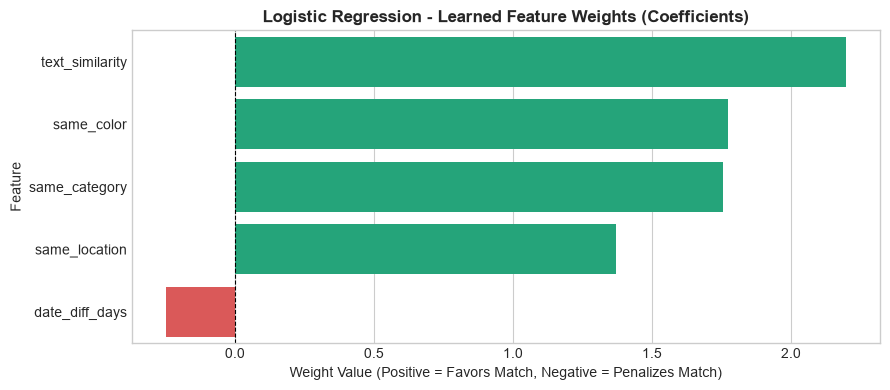

In [11]:
coef_df = pd.DataFrame({
    "Feature": feature_cols,
    "Coefficient (Weight)": log_reg.coef_[0]
}).sort_values(by="Coefficient (Weight)", ascending=False)

plt.figure(figsize=(9, 4))
colors = ['#10B981' if w > 0 else '#EF4444' for w in coef_df["Coefficient (Weight)"]]
sns.barplot(x="Coefficient (Weight)", y="Feature", data=coef_df, palette=colors)
plt.axvline(0, color='black', linestyle='--', linewidth=0.8)
plt.title("Logistic Regression - Learned Feature Weights (Coefficients)", fontweight='bold')
plt.xlabel("Weight Value (Positive = Favors Match, Negative = Penalizes Match)")
plt.tight_layout()
plt.show()

print("Learned Weights Summary:")
for _, row in coef_df.iterrows():
    print(f"  - {row['Feature']:15s}: {row['Coefficient (Weight)']:+.4f}")
print(f"  - Intercept (Base Prior): {log_reg.intercept_[0]:+.4f}")


## 🧩 Step 7: Algorithm D - Unsupervised Learning (K-Means Clustering)

### Concept:
- **Task**: Group item descriptions into distinct topic clusters *without using any human labels*.
- **How it works**:
  1. Computes TF-IDF vector for each description.
  2. Partitions descriptions into $K$ clusters by iteratively assigning points to the nearest centroid.
  3. Reduces dimensionality to 2D using **PCA (Principal Component Analysis)** for scatter plot visualization.


Top Keywords Discovered Per Cluster:
  - Cluster #0: leather, brown, zipper, wallet
  - Cluster #1: keys, silver, grey, red
  - Cluster #2: black, fitbit, laptop, blue
  - Cluster #3: phone, case, blue, green


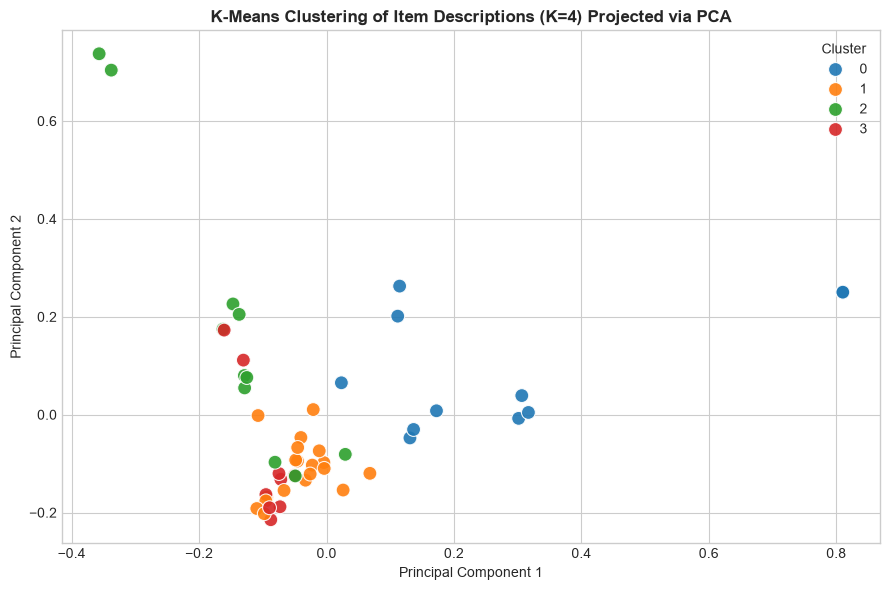

In [12]:
from ml_models import perform_kmeans_clustering

descriptions_sample = df_items["description"].tolist()[:50]
cluster_labels, coords_2d, top_keywords = perform_kmeans_clustering(descriptions_sample, n_clusters=4)

df_clusters = pd.DataFrame({
    "description": descriptions_sample,
    "cluster": cluster_labels,
    "pca_x": [c[0] for c in coords_2d],
    "pca_y": [c[1] for c in coords_2d]
})

plt.figure(figsize=(9, 6))
sns.scatterplot(
    x="pca_x",
    y="pca_y",
    hue="cluster",
    palette="tab10",
    data=df_clusters,
    s=100,
    alpha=0.9
)
plt.title("K-Means Clustering of Item Descriptions (K=4) Projected via PCA", fontweight='bold')
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend(title="Cluster")
plt.tight_layout()
plt.show()

print("Top Keywords Discovered Per Cluster:")
for cl_id, terms in top_keywords.items():
    print(f"  - Cluster #{cl_id}: {', '.join(terms)}")


## 💾 Step 8: SQLite Database Storage & Persistence

The application uses an SQLite database (`lost_found.db`) so reports persist even after restarting the notebook or app.


In [13]:
from database import init_db, seed_sample_reports_if_empty, get_reports, add_report, get_summary_stats

# Initialize database and populate sample reports
init_db()
seed_sample_reports_if_empty()

stats = get_summary_stats()
print("Database Statistics:")
print(f"  - Total Lost Items : {stats['total_lost']}")
print(f"  - Total Found Items: {stats['total_found']}")
print(f"  - Resolved Cases   : {stats['total_resolved']}")

# Inspect reports stored in SQLite
reports_df = pd.DataFrame(get_reports())
reports_df[["id", "report_type", "item_name", "category", "color", "location", "report_date", "status"]].head(8)


Database Statistics:
  - Total Lost Items : 8
  - Total Found Items: 9
  - Resolved Cases   : 0


## 🎯 Step 9: Complete End-to-End Lost & Found Matching Demonstration

Now we demonstrate the full pipeline:
1. Select a lost report.
2. Compare against all found reports.
3. Calculate text similarity, categorical matching, date proximity.
4. Pass features to the trained **Logistic Regression** model.
5. Rank and display the top 5 candidate matches with **Explainable AI (XAI)** reasoning.


In [14]:
from matching import find_top_matches

# Retrieve all lost and found reports from SQLite
lost_reports = get_reports(report_type="lost")
found_reports = get_reports(report_type="found")

# Let's test with a lost item: "Black Leather Wallet"
target_lost = [r for r in lost_reports if "Wallet" in r["item_name"]][0]

print("=" * 80)
print(f"TARGET LOST ITEM: #{target_lost['id']} - {target_lost['item_name']}")
print(f"Category: {target_lost['category']} | Color: {target_lost['color']} | Location: {target_lost['location']}")
print(f"Date Lost: {target_lost['report_date']}")
print(f"Description: '{target_lost['description']}'")
print("=" * 80)

# Run matching engine
top_5_matches = find_top_matches(target_lost, found_reports, top_n=5)

for rank, match in enumerate(top_5_matches, 1):
    cand = match["found_report"]
    status_str = "✅ POTENTIAL MATCH" if match["is_potential_match"] else "⚠️ LOW PROBABILITY"
    
    print(f"\n[Rank #{rank}] {cand['item_name']} (Report #{cand['id']}) - {status_str}")
    print(f"  - Composite Match Score : {match['composite_score']}%")
    print(f"  - ML Match Probability  : {match['logistic_regression_prob']}%")
    print(f"  - TF-IDF Text Similarity: {match['text_similarity']}%")
    print(f"  - Found At              : {cand['location']} on {cand['report_date']} (Date Diff: {match['date_diff_days']} days)")
    print(f"  - Why Suggested:")
    for r in match["reasons"]:
        print(f"      • {r}")


TARGET LOST ITEM: #1 - Black Leather Wallet
Category: Wallet | Color: Black | Location: Central Library
Date Lost: 2026-11-20
Description: 'Lost my black leather bi-fold wallet on the 2nd floor study table. Has student ID and metro pass.'

[Rank #1] Dark Leather Wallet (Report #8) - ✅ POTENTIAL MATCH
  - Composite Match Score : 79.9%
  - ML Match Probability  : 98.6%
  - TF-IDF Text Similarity: 42.5%
  - Found At              : Central Library on 2026-11-20 (Date Diff: 0 days)
  - Why Suggested:
      • Matching category: Both are 'Wallet'
      • Same location: Reported at 'Central Library'
      • Matching color: Both listed as 'Black'
      • Moderate description similarity (42% TF-IDF cosine match)
      • Reported on the exact same date

[Rank #2] phone with black cover (Report #18) - ✅ POTENTIAL MATCH
  - Composite Match Score : 34.7%
  - ML Match Probability  : 67.2%
  - TF-IDF Text Similarity: 7.4%
  - Found At              : Central Library on 2026-11-24 (Date Diff: 4 days)
  

## 🌐 Step 10: Streamlit Web Application Companion

To experience this project with an interactive web UI with forms, dashboards, and search filters, run the Streamlit app in your terminal:

```bash
streamlit run app.py
```

It uses the exact same `database.py`, `ml_models.py`, and `matching.py` modules tested in this notebook!


## 🎓 Step 11: Viva Preparation & Examiner Q&A Guide

#### Q1: What is the difference between Supervised and Unsupervised Learning in this project?
> **Answer**:
> - **Supervised Learning**: Models learn from labeled training data $(X, y)$.
>   - **Random Forest**: Learns to map text descriptions $\rightarrow$ 7 item categories.
>   - **Logistic Regression**: Learns to map 5 comparison features $\rightarrow$ binary match label (`1` or `0`).
> - **Unsupervised Learning**: Models learn without human labels.
>   - **K-Means Clustering**: Groups item descriptions into clusters based on geometric distance in TF-IDF vector space.

#### Q2: Why use TF-IDF instead of simple word counts (Bag of Words)?
> **Answer**: Bag of Words only counts frequencies. Common words like *"lost"*, *"found"*, or *"near"* would get high counts and drown out the signal. TF-IDF applies an inverse document frequency penalty to frequent words, amplifying distinctive keywords like *"Casio"*, *"AirPods"*, or *"leather"*.

#### Q3: Why is Logistic Regression used instead of Cosine Similarity alone?
> **Answer**: Cosine similarity only measures textual vocabulary overlap. Two items might share similar words but be lost in completely different locations or months apart. Logistic Regression combines text similarity, category matching, color matching, location matching, and date difference, learning the optimal mathematical weights for each.

#### Q4: Why is the output called a "Potential Match" instead of a guarantee?
> **Answer**: Machine Learning models produce probabilistic estimates based on feature overlap. Real-world verification (e.g., asking the claimant to unlock a phone, verify ID cards inside a wallet, or produce a receipt) is always required before physical handover.

---
### 🏁 Conclusion
All machine learning objectives have been achieved using clean, explainable, traditional Scikit-Learn algorithms, with zero external AI APIs or deep learning dependencies.
